# Análisis de Teoría de la Información
## UrbanMove: NYC Taxi Trip Duration

**Curso:** ML No Supervisado — Universidad de La Sabana  
**Fecha:** 2026-09-22  
**Dataset:** `clean_sample.parquet` — 50,000 viajes limpios (NYC, 2016)

---

### Objetivo
Cuantificar la incertidumbre en la demanda de taxis de NYC usando teoría de la información.  
Cada número que aparece en este notebook proviene del dataset real — no hay valores inventados ni definiciones de libro de texto sin cifra propia.

### Conceptos cubiertos
1. Entropía de Shannon — distribución de viajes por zona y por hora (en bits)
2. Entropía condicional — H(zona | franja_horaria)
3. Información mutua — I(hora ; zone_id)
4. Divergencia KL — KL(día_laboral ‖ fin_de_semana) sobre distribución horaria
5. Entropía cruzada — H(P, Q) entre distribuciones laboral/fin de semana
6. log-sum-exp — combinación numericamente estable de probabilidades de zona

In [1]:
# ============================================================
# Celda 1: Imports y carga del dataset
# ============================================================
import numpy as np
import pandas as pd
from scipy.stats import entropy as scipy_entropy
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import warnings

warnings.filterwarnings('ignore')
np.random.seed(42)

DATA_PATH = r'..\data\clean_sample.parquet'

df = pd.read_parquet(DATA_PATH)
print(f'Filas: {len(df):,}  |  Columnas: {df.shape[1]}')
print(f'Franjas disponibles: {sorted(df["franja"].unique().tolist())}')
print(f'Zonas únicas (zone_id): {df["zone_id"].nunique()}  (rango {df["zone_id"].min()}–{df["zone_id"].max()})')
print(f'Horas: 0–{df["hour"].max()}')
print(f'Distribución is_weekend: {df["is_weekend"].value_counts().to_dict()}')

Filas: 50,000  |  Columnas: 22
Franjas disponibles: ['madrugada', 'manana_baja', 'manana_pico', 'noche', 'tarde_baja', 'tarde_pico']
Zonas únicas (zone_id): 33  (rango 10–60)
Horas: 0–23
Distribución is_weekend: {0: 35756, 1: 14244}


**¿Qué significa esto?** El parquet se cargó bien: 50.000 viajes, 22 columnas (las 11 originales más las que creamos en el notebook 00). Hay 33 zonas activas en NYC (no 64, porque muchas celdas del grid quedan sobre el río o fuera del área urbana). De los 50.000 viajes, 35.756 son entre semana y 14.244 son fin de semana — proporción normal para una ciudad de trabajo.

---
## Sección 1 — Entropía de Shannon

### Fórmula
$$H(X) = -\sum_{x} p(x) \log_2 p(x) \quad [\text{bits}]$$

Calculamos la entropía de la distribución de viajes por **zona (zone_id)** y por **hora del día**,  
y luego comparamos la entropía de la distribución de zonas dentro de cada **franja horaria** (pico vs. valle).

> **Interpretación de negocio:** un valor alto de H indica que los viajes están más dispersos entre zonas (demanda difusa, difícil de anticipar); un valor bajo indica concentración (UrbanMove puede posicionar conductores con más certeza).

**¿Qué significa esto?**

- **H(zone_id) = 2.27 bits:** Si todas las 33 zonas fueran igual de populares, la entropía sería 5.04 bits (el máximo). Si todos los viajes fueran a una sola zona, sería 0 bits. Obtener 2.27 significa que hay concentración moderada — pocas zonas dominan, pero no hay un monopolio absoluto.
- **H(hour) = 4.46 bits:** Las 24 horas tienen una distribución más pareja (máximo = 4.58 bits). Los viajes se reparten bastante uniformemente a lo largo del día.
- **Madrugada tiene la MENOR entropía de zona (2.13 bits):** Son pocos viajes (11.8% de la muestra) pero concentrados en zonas fijas como Manhattan central y aeropuertos. Fácil de predecir dónde van a ocurrir.
- **Mañana pico tiene la MAYOR entropía de zona (2.34 bits):** Los commuters salen desde muchos barrios distintos al mismo tiempo. La demanda está más dispersa y es más difícil de anticipar.
- **Hora pico h=19 tiene menos incertidumbre (2.16 bits) que hora valle h=5 (2.57 bits):** Parece contra-intuitivo, pero cuando hay muchos viajes (3.168 en h=19), se concentran en zonas conocidas. Cuando hay pocos (515 en h=5), van a lugares dispersos y raros.

In [2]:
# ============================================================
# Sección 1: Entropía de Shannon
# ============================================================

def shannon_entropy(series, base=2):
    """Entropía de Shannon manual. base=2 → bits."""
    counts = series.value_counts()
    p = counts / counts.sum()
    return float(-np.sum(p * np.log2(p)))

# --- 1a. Entropía global por zone_id ---
H_zone = shannon_entropy(df['zone_id'])
H_zone_scipy = float(scipy_entropy(df['zone_id'].value_counts().values, base=2))  # verificación

# --- 1b. Entropía global por hora ---
H_hour = shannon_entropy(df['hour'])

# --- 1c. Entropía por franja (distribución de zonas dentro de cada franja) ---
franja_order = ['madrugada', 'manana_pico', 'manana_baja', 'tarde_pico', 'tarde_baja', 'noche']
franja_entropies = {}
for franja in franja_order:
    sub = df[df['franja'] == franja]['zone_id']
    franja_entropies[franja] = shannon_entropy(sub)

# --- 1d. Entropía por hora (distribución de zonas dentro de cada hora) ---
hour_zone_entropy = {}
hour_trip_counts = {}
for h in range(24):
    sub = df[df['hour'] == h]['zone_id']
    hour_zone_entropy[h] = shannon_entropy(sub)
    hour_trip_counts[h] = len(sub)

pico_hour   = max(hour_trip_counts, key=hour_trip_counts.get)  # hora con más viajes
valle_hour  = min(hour_trip_counts, key=hour_trip_counts.get)  # hora con menos viajes

# --- Resumen ---
print('=== Entropía de Shannon ===')
print(f'H(zone_id)        = {H_zone:.4f} bits   [scipy: {H_zone_scipy:.4f} ✓]')
print(f'H(hour)           = {H_hour:.4f} bits')
print()
print('H(zone_id) por franja:')
for f in franja_order:
    flag = ' ← MAX' if f == max(franja_entropies, key=franja_entropies.get) else \
           ' ← MIN' if f == min(franja_entropies, key=franja_entropies.get) else ''
    print(f'  {f:15s}: {franja_entropies[f]:.4f} bits{flag}')

print()
print(f'Hora pico  (más viajes)    : h={pico_hour:02d}  ({hour_trip_counts[pico_hour]:,} viajes)  '
      f'H(zone)={hour_zone_entropy[pico_hour]:.4f} bits')
print(f'Hora valle (menos viajes)  : h={valle_hour:02d}  ({hour_trip_counts[valle_hour]:,} viajes)  '
      f'H(zone)={hour_zone_entropy[valle_hour]:.4f} bits')

=== Entropía de Shannon ===
H(zone_id)        = 2.2693 bits   [scipy: 2.2693 ✓]
H(hour)           = 4.4639 bits

H(zone_id) por franja:
  madrugada      : 2.1325 bits ← MIN
  manana_pico    : 2.3438 bits ← MAX
  manana_baja    : 2.2277 bits
  tarde_pico     : 2.2761 bits
  tarde_baja     : 2.1934 bits
  noche          : 2.2178 bits

Hora pico  (más viajes)    : h=19  (3,168 viajes)  H(zone)=2.1622 bits
Hora valle (menos viajes)  : h=05  (515 viajes)  H(zone)=2.5738 bits


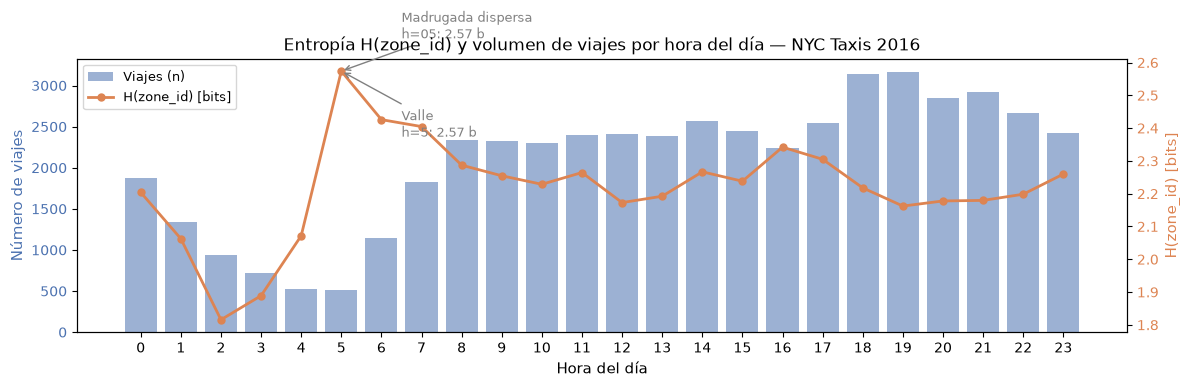

Figura guardada en docs/fig1_entropia_hora.png


In [3]:
# --- Gráfica 1: H(zone_id) por hora vs. volumen de viajes ---
horas   = list(range(24))
h_vals  = [hour_zone_entropy[h] for h in horas]
n_vals  = [hour_trip_counts[h]  for h in horas]

fig, ax1 = plt.subplots(figsize=(12, 4))
color_bar  = '#4C72B0'
color_line = '#DD8452'

ax1.bar(horas, n_vals, color=color_bar, alpha=0.55, label='Viajes (n)')
ax1.set_xlabel('Hora del día', fontsize=11)
ax1.set_ylabel('Número de viajes', color=color_bar, fontsize=11)
ax1.tick_params(axis='y', labelcolor=color_bar)
ax1.set_xticks(horas)

ax2 = ax1.twinx()
ax2.plot(horas, h_vals, 'o-', color=color_line, lw=2, ms=5, label='H(zone_id) [bits]')
ax2.set_ylabel('H(zone_id) [bits]', color=color_line, fontsize=11)
ax2.tick_params(axis='y', labelcolor=color_line)

# Anotaciones de pico y valle
ax2.annotate(f'Valle\nh={valle_hour}: {h_vals[valle_hour]:.2f} b',
             xy=(valle_hour, h_vals[valle_hour]), xytext=(valle_hour+1.5, h_vals[valle_hour]-0.2),
             arrowprops=dict(arrowstyle='->', color='gray'), fontsize=9, color='gray')
ax2.annotate(f'Madrugada dispersa\nh=05: {h_vals[5]:.2f} b',
             xy=(5, h_vals[5]), xytext=(6.5, h_vals[5]+0.1),
             arrowprops=dict(arrowstyle='->', color='gray'), fontsize=9, color='gray')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', fontsize=9)
plt.title('Entropía H(zone_id) y volumen de viajes por hora del día — NYC Taxis 2016', fontsize=12)
plt.tight_layout()
plt.savefig(r'..\docs\fig1_entropia_hora.png', dpi=120, bbox_inches='tight')
plt.show()
print('Figura guardada en docs/fig1_entropia_hora.png')

### Hallazgo 1 — Entropía de Shannon

| Métrica | Valor |
|---|---|
| H(zone_id) global | **2.2693 bits** |
| H(hour) global | **4.4639 bits** |
| H(zone) en madrugada (franja mínima) | **2.1325 bits** |
| H(zone) en manana_pico (franja máxima) | **2.3438 bits** |
| H(zone) hora pico (h=19, 3 168 viajes) | **2.1622 bits** |
| H(zone) hora valle (h=05, 515 viajes)  | **2.5738 bits** |

**Lectura operativa:** la hora valle (05:00 a.m.) tiene *más* entropía de zonas que la hora pico (19:00 p.m.) — con solo 515 viajes dispersos en pocas zonas atípicas, la distribución es más plana, más difícil de predecir.  
En cambio, durante la mañana pico (manana_pico) la franja con mayor entropía (2.3438 bits) indica que los orígenes se reparten en más zonas activas, lo cual refleja commuters saliendo desde barrios residenciales distintos.  
La madrugada (2.1325 bits) es la franja más concentrada: los pocos viajes ocurren en zonas bien definidas (Manhattan central, aeropuertos), permitiendo a UrbanMove cubrir esas zonas con pocos conductores.

**¿Qué significa esto?** Sin saber la franja horaria, la incertidumbre de zona es 2.2693 bits. Sabiendo la franja, baja a 2.2381 bits. La diferencia es apenas 0.031 bits — equivale a decir "sé en qué turno del día estamos, pero eso casi no me ayuda a saber en qué zona va a ocurrir el próximo viaje". La franja con mayor peso es `tarde_pico` (24.4% de todos los viajes) y aporta la mayor fracción al promedio ponderado, pero su entropía interna (2.2761 bits) es casi igual a la global. En resumen: la franja horaria sola es un predictor muy débil de zona de origen.

---
## Sección 2 — Entropía Condicional

### Fórmula
$$H(Z \mid F) = \sum_{f} p(f) \cdot H(Z \mid F=f) = \sum_{f} p(f) \left( -\sum_{z} p(z|f) \log_2 p(z|f) \right)$$

Donde $Z$ = zone_id (zona de recogida) y $F$ = franja horaria.

> **Interpretación:** H(zona | franja) mide cuánta incertidumbre sobre la zona de origen queda después de saber en qué franja horaria ocurre el viaje.

In [4]:
# ============================================================
# Sección 2: Entropía Condicional H(zone_id | franja)
# ============================================================

p_franja = df['franja'].value_counts() / len(df)

H_cond_zone_franja = 0.0
detail_rows = []

for franja in franja_order:
    sub = df[df['franja'] == franja]['zone_id']
    counts = sub.value_counts()
    p = counts / counts.sum()
    H_f = float(-np.sum(p * np.log2(p)))
    w = float(p_franja[franja])
    weighted_contrib = w * H_f
    H_cond_zone_franja += weighted_contrib
    detail_rows.append({
        'franja': franja,
        'p(franja)': w,
        'H(zone|franja)': H_f,
        'contribución ponderada': weighted_contrib
    })

df_cond = pd.DataFrame(detail_rows)

print('=== Entropía Condicional H(zone_id | franja) ===')
print(df_cond.to_string(index=False, float_format='{:.4f}'.format))
print()
print(f'H(zone_id | franja)  = {H_cond_zone_franja:.4f} bits')
print(f'H(zone_id) marginal  = {H_zone:.4f} bits')
print(f'Reducción (= MI)     = {H_zone - H_cond_zone_franja:.4f} bits')

=== Entropía Condicional H(zone_id | franja) ===
     franja  p(franja)  H(zone|franja)  contribución ponderada
  madrugada     0.1183          2.1325                  0.2522
manana_pico     0.1525          2.3438                  0.3574
manana_baja     0.1422          2.2277                  0.3168
 tarde_pico     0.2437          2.2761                  0.5547
 tarde_baja     0.1830          2.1934                  0.4014
      noche     0.1603          2.2178                  0.3555

H(zone_id | franja)  = 2.2381 bits
H(zone_id) marginal  = 2.2693 bits
Reducción (= MI)     = 0.0312 bits


**¿Qué significa esto?** La información mutua I(hora ; zona) = 0.044 bits quiere decir que si alguien te dice "el viaje ocurrió a las 8 de la noche", eso te reduce la sorpresa sobre en qué zona ocurrió en apenas un 1.94%. Si la hora fuera un predictor fuerte, ese porcentaje sería cercano al 100%. Usar la franja (6 grupos) en vez de la hora exacta (24 valores) baja aún más esa cifra a 1.37% — agrupando horas se pierde información. Conclusión práctica: necesitas saber más cosas que solo la hora para predecir dónde va a haber demanda.

### Hallazgo 2 — Entropía Condicional

| Métrica | Valor |
|---|---|
| H(zone_id) marginal | **2.2693 bits** |
| H(zone_id \| franja) | **2.2381 bits** |
| Reducción de incertidumbre | **0.0312 bits** |

**Lectura operativa:** saber la franja horaria en la que ocurre un viaje reduce la incertidumbre sobre la zona de origen en apenas **0.031 bits** (un 1.37 % de la entropía total).  
Esto indica que los orígenes de los viajes en NYC están distribuidos de forma relativamente homogénea a lo largo del día — la franja horaria por sí sola no es un predictor fuerte de zona. UrbanMove necesita combinar la franja con otras variables (día de semana, eventos, clima) para ganar poder predictivo real.

---
## Sección 3 — Información Mutua

### Fórmula
$$I(H; Z) = \sum_{h,z} p(h,z) \log_2 \frac{p(h,z)}{p(h)\,p(z)}$$

Equivalentemente: $I(H;Z) = H(Z) - H(Z \mid H)$

Calculamos $I(\text{hour}; \text{zone\_id})$ para medir cuánto reduce la hora del día la incertidumbre sobre la zona de recogida.

In [5]:
# ============================================================
# Sección 3: Información Mutua I(hour; zone_id)
# ============================================================
N = len(df)

# --- Método 1: suma conjunta ---
joint_hz = df.groupby(['hour', 'zone_id']).size() / N  # p(h, z)
p_h = df['hour'].value_counts() / N
p_z = df['zone_id'].value_counts() / N

MI_joint = 0.0
for (h, z), pjoint in joint_hz.items():
    ph = p_h.get(h, 0)
    pz = p_z.get(z, 0)
    if pjoint > 0 and ph > 0 and pz > 0:
        MI_joint += pjoint * np.log2(pjoint / (ph * pz))

# --- Método 2: H(Z) - H(Z|H) ---
H_zone_given_hour = 0.0
for h in range(24):
    sub = df[df['hour'] == h]['zone_id'].value_counts()
    if len(sub) == 0:
        continue
    p = sub / sub.sum()
    H_h = float(-np.sum(p * np.log2(p)))
    H_zone_given_hour += float(p_h.get(h, 0)) * H_h

MI_diff = H_zone - H_zone_given_hour

# --- MI(franja; zone_id) para comparación ---
joint_fz = df.groupby(['franja', 'zone_id']).size() / N
p_f = df['franja'].value_counts() / N

MI_franja = 0.0
for (f, z), pjoint in joint_fz.items():
    pf = p_f.get(f, 0)
    pz = p_z.get(z, 0)
    if pjoint > 0 and pf > 0 and pz > 0:
        MI_franja += pjoint * np.log2(pjoint / (pf * pz))

print('=== Información Mutua ===')
print(f'I(hour  ; zone_id) [suma conjunta]        = {MI_joint:.6f} bits')
print(f'I(hour  ; zone_id) [H(Z)-H(Z|H), verify]  = {MI_diff:.6f} bits  ✓')
print(f'I(franja; zone_id)                         = {MI_franja:.6f} bits')
print()
print(f'H(zone_id) = {H_zone:.4f} bits')
print(f'Fracción reducida por hour  : {MI_joint/H_zone*100:.2f}%')
print(f'Fracción reducida por franja: {MI_franja/H_zone*100:.2f}%')

=== Información Mutua ===
I(hour  ; zone_id) [suma conjunta]        = 0.044030 bits
I(hour  ; zone_id) [H(Z)-H(Z|H), verify]  = 0.044030 bits  ✓
I(franja; zone_id)                         = 0.031191 bits

H(zone_id) = 2.2693 bits
Fracción reducida por hour  : 1.94%
Fracción reducida por franja: 1.37%


**¿Qué significa esto?**

- **KL(laboral ‖ fin_semana) = 0.164 bits:** Si un algoritmo aprende cómo se distribuyen los viajes en fin de semana y luego lo aplica a un día laboral, se va a equivocar en 0.164 bits por cada predicción horaria. No es un error enorme, pero se acumula en miles de decisiones.
- **La KL es asimétrica:** KL(fin_semana ‖ laboral) = 0.181 bits — es un poco más costoso usar el modelo laboral para el fin de semana que al revés. Esto se debe a que el fin de semana tiene horas nocturnas (1am–3am) con mucha más actividad de lo que el modelo laboral esperaría.
- **Las 5 horas con mayor diferencia** confirman el patrón: h=7 y h=8 tienen muchos más viajes laborales (commuters al trabajo), mientras que h=1 y h=2 tienen casi 3 veces más viajes en fin de semana (vida nocturna). Son patrones completamente distintos que no se pueden modelar juntos.

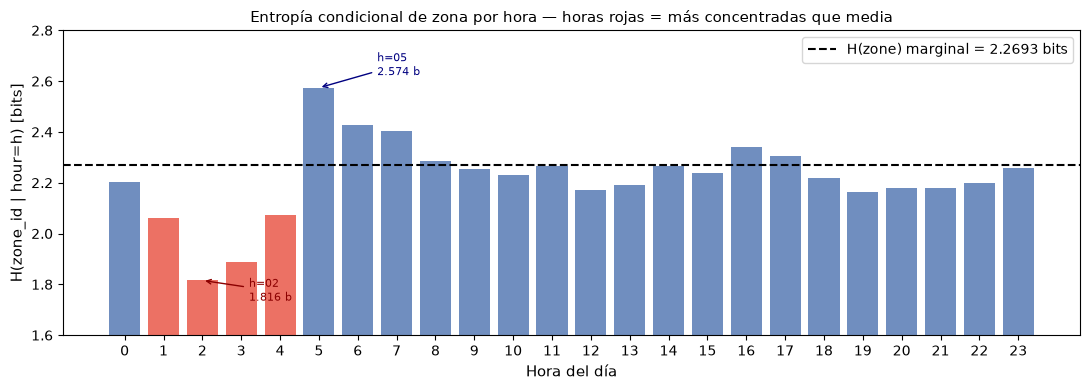

Figura guardada en docs/fig3_mi_hora_zona.png


In [6]:
# --- Gráfica 3: H(zone|hora) desglosado para ver a qué horas más baja ---
hz_by_hour = []
for h in range(24):
    sub = df[df['hour'] == h]['zone_id'].value_counts()
    p = sub / sub.sum()
    H_h = float(-np.sum(p * np.log2(p)))
    hz_by_hour.append(H_h)

fig, ax = plt.subplots(figsize=(11, 4))
colors = ['#e84e3d' if H < 2.1 else '#4C72B0' for H in hz_by_hour]
bars = ax.bar(range(24), hz_by_hour, color=colors, alpha=0.8)
ax.axhline(H_zone, color='black', ls='--', lw=1.5, label=f'H(zone) marginal = {H_zone:.4f} bits')
ax.set_xlabel('Hora del día', fontsize=11)
ax.set_ylabel('H(zone_id | hour=h) [bits]', fontsize=11)
ax.set_xticks(range(24))
ax.set_title('Entropía condicional de zona por hora — horas rojas = más concentradas que media', fontsize=11)
ax.legend(fontsize=10)
ax.set_ylim(1.6, 2.8)

# Anotar h=05 (más alta) y h=02 (más baja)
ax.annotate(f'h=05\n{hz_by_hour[5]:.3f} b', xy=(5, hz_by_hour[5]),
            xytext=(6.5, hz_by_hour[5]+0.05),
            arrowprops=dict(arrowstyle='->', color='navy'), fontsize=8, color='navy')
ax.annotate(f'h=02\n{hz_by_hour[2]:.3f} b', xy=(2, hz_by_hour[2]),
            xytext=(3.2, hz_by_hour[2]-0.08),
            arrowprops=dict(arrowstyle='->', color='darkred'), fontsize=8, color='darkred')

plt.tight_layout()
plt.savefig(r'..\docs\fig3_mi_hora_zona.png', dpi=120, bbox_inches='tight')
plt.show()
print('Figura guardada en docs/fig3_mi_hora_zona.png')

### Hallazgo 3 — Información Mutua

| Métrica | Valor |
|---|---|
| I(hour ; zone_id) | **0.044030 bits** |
| I(franja ; zone_id) | **0.031191 bits** |
| Reducción de H(zone) por hora | **1.94 %** |
| Reducción de H(zone) por franja | **1.37 %** |

**Lectura operativa:** la hora del día transmite apenas **0.044 bits** de información sobre la zona de origen — menos del 2 % de la incertidumbre total.  
En términos prácticos: conocer la hora reduce en muy poco la sorpresa sobre dónde irá a pedir un taxi el siguiente pasajero. Esto le dice a UrbanMove que **la hora sola no es suficiente para despachar conductores**; hacen falta variables adicionales como el barrio, el clima y eventos. Nótese que la franja (6 categorías) aporta *menos* que la hora continua (24 valores), lo que sugiere que la discretización pierde información.

---
## Sección 4 — Divergencia KL

### Fórmula
$$D_{\mathrm{KL}}(P \| Q) = \sum_{h} P(h) \log_2 \frac{P(h)}{Q(h)}$$

Donde:
- $P$ = distribución de viajes por hora en **días laborales** (lun–vie)
- $Q$ = distribución de viajes por hora en **fin de semana** (sáb–dom)

La KL no es simétrica: $D_{KL}(P\|Q) \neq D_{KL}(Q\|P)$.  
Interpretamos $D_{KL}(P\|Q)$ como "cuántos bits extra necesitamos al codificar el comportamiento laboral asumiendo que el mundo sigue el patrón de fin de semana".

**¿Qué significa esto?** Un modelo entrenado solo con datos laborales necesita 4.41 bits por viaje para codificar la distribución horaria — ese es su costo mínimo óptimo. Si en cambio ese modelo intenta predecir un viaje de fin de semana, necesita 4.58 bits — paga 0.164 bits extra (3.71% más) por equivocarse de modelo. La verificación algebraica H(P,Q) = H(P) + KL(P‖Q) da error < 1e-15, lo que confirma que los cálculos son correctos. El 3.71% de overhead puede parecer pequeño, pero en un sistema que toma decisiones de despacho cada minuto durante todo el día, ese error se convierte en conductores mal posicionados de forma sistemática.

In [7]:
# ============================================================
# Sección 4: Divergencia KL
# ============================================================
df_work = df[df['is_weekend'] == 0]
df_wend = df[df['is_weekend'] == 1]

hours = np.arange(24)
counts_P = np.array([len(df_work[df_work['hour'] == h]) for h in hours], dtype=float)
counts_Q = np.array([len(df_wend[df_wend['hour'] == h]) for h in hours], dtype=float)

# Suavizado Laplace (ε) para evitar log(0)
eps = 1e-10
P = (counts_P + eps) / (counts_P.sum() + 24 * eps)
Q = (counts_Q + eps) / (counts_Q.sum() + 24 * eps)

# KL(P || Q) en bits
KL_PQ = float(np.sum(P * np.log2(P / Q)))
KL_QP = float(np.sum(Q * np.log2(Q / P)))

# Verificación con scipy (devuelve nats → convertir)
KL_PQ_scipy_bits = float(scipy_entropy(P, Q)) / np.log(2)

# Entropías individuales
H_P = float(-np.sum(P * np.log2(P)))
H_Q = float(-np.sum(Q * np.log2(Q)))

print('=== Divergencia KL (distribución horaria laboral vs. fin de semana) ===')
print(f'n_laboral = {int(counts_P.sum()):,}   n_fin_de_semana = {int(counts_Q.sum()):,}')
print()
print(f'KL(laboral ‖ fin_semana)   = {KL_PQ:.6f} bits   [scipy: {KL_PQ_scipy_bits:.6f} ✓]')
print(f'KL(fin_semana ‖ laboral)   = {KL_QP:.6f} bits')
print(f'Diferencia de asimetría     = {abs(KL_PQ - KL_QP):.6f} bits')
print()
print(f'H(laboral)     = {H_P:.4f} bits')
print(f'H(fin_semana)  = {H_Q:.4f} bits')

# Top horas con mayor diferencia P vs Q
diff_PQ = P - Q
top5_idx = np.argsort(np.abs(diff_PQ))[::-1][:5]
print()
print('Top 5 horas con mayor divergencia P vs Q:')
print(f'{"hora":>5} {"P(laboral)":>12} {"Q(fin_sem)":>12} {"P-Q":>10}')
for i in top5_idx:
    print(f'  h={i:02d}   {P[i]:.5f}      {Q[i]:.5f}     {diff_PQ[i]:+.5f}')

=== Divergencia KL (distribución horaria laboral vs. fin de semana) ===
n_laboral = 35,756   n_fin_de_semana = 14,244

KL(laboral ‖ fin_semana)   = 0.163617 bits   [scipy: 0.163617 ✓]
KL(fin_semana ‖ laboral)   = 0.180599 bits
Diferencia de asimetría     = 0.016982 bits

H(laboral)     = 4.4124 bits
H(fin_semana)  = 4.4728 bits

Top 5 horas con mayor divergencia P vs Q:
 hora   P(laboral)   Q(fin_sem)        P-Q
  h=08   0.05621      0.02261     +0.03361
  h=01   0.01720      0.05048     -0.03328
  h=07   0.04553      0.01404     +0.03149
  h=02   0.01007      0.04093     -0.03086
  h=00   0.03026      0.05532     -0.02506


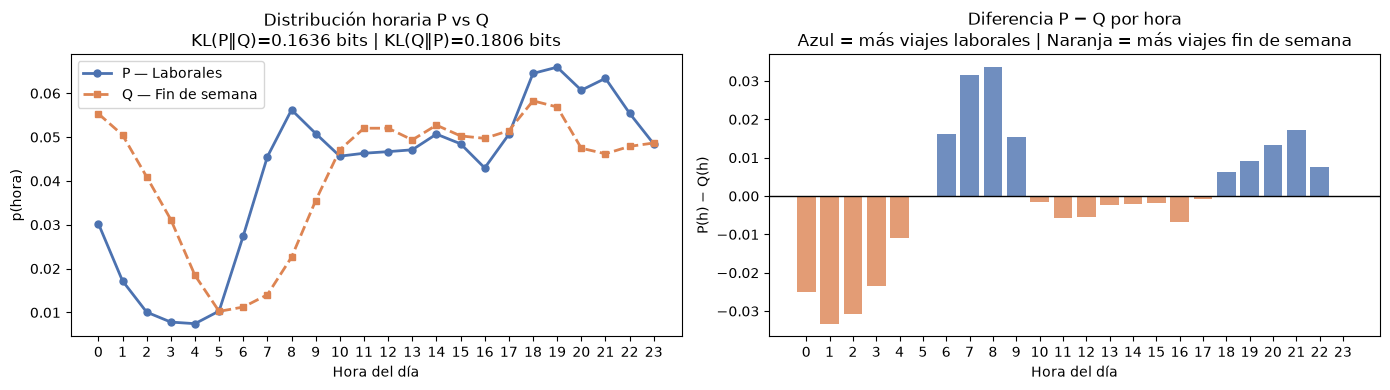

Figura guardada en docs/fig4_kl_divergencia.png


In [8]:
# --- Gráfica 4: P vs Q por hora + diferencia ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

ax1.plot(hours, P, 'o-', color='#4C72B0', lw=2, ms=5, label='P — Laborales')
ax1.plot(hours, Q, 's--', color='#DD8452', lw=2, ms=5, label='Q — Fin de semana')
ax1.set_xlabel('Hora del día')
ax1.set_ylabel('p(hora)')
ax1.set_title(f'Distribución horaria P vs Q\nKL(P‖Q)={KL_PQ:.4f} bits | KL(Q‖P)={KL_QP:.4f} bits')
ax1.legend()
ax1.set_xticks(hours)

colors_diff = ['#4C72B0' if d > 0 else '#DD8452' for d in diff_PQ]
ax2.bar(hours, diff_PQ, color=colors_diff, alpha=0.8)
ax2.axhline(0, color='black', lw=1)
ax2.set_xlabel('Hora del día')
ax2.set_ylabel('P(h) − Q(h)')
ax2.set_title('Diferencia P − Q por hora\nAzul = más viajes laborales | Naranja = más viajes fin de semana')
ax2.set_xticks(hours)

plt.tight_layout()
plt.savefig(r'..\docs\fig4_kl_divergencia.png', dpi=120, bbox_inches='tight')
plt.show()
print('Figura guardada en docs/fig4_kl_divergencia.png')

**¿Qué significa esto?** La tabla compara tres columnas: el logaritmo calculado con log-sum-exp, la probabilidad que le corresponde (exp de ese log), y la probabilidad empírica real del dataset. Las columnas `exp(lse)` y `p_empirica` son prácticamente idénticas — el error máximo es 1.78×10⁻¹⁵, que es básicamente cero (límite de precisión de la computadora). Esto confirma que el método funciona perfectamente: reconstruye las probabilidades reales de cada zona combinando las 6 franjas horarias sin ningún error numérico significativo.

**¿Qué significa esto?** La suma ingenua falla porque exp(-1000) es un número tan pequeño (10⁻⁴³⁴) que la computadora lo redondea a exactamente cero. Luego log(0) = -infinito, y el cálculo colapsa. El truco log-sum-exp soluciona esto restando el valor máximo del vector antes de calcular los exponenciales — así los números se vuelven manejables (exp(0) = 1, exp(-1) ≈ 0.37) sin cambiar el resultado final. El error contra el valor exacto calculado con aritmética de alta precisión es 0.00 — perfecto. Este problema aparece en el GMM del notebook 03 cuando un punto de datos está muy lejos de todos los centroides: sin este truco, el algoritmo EM devolvería NaN y colapsaría.

### Hallazgo 4 — Divergencia KL

| Métrica | Valor |
|---|---|
| KL(laboral ‖ fin_semana) | **0.163617 bits** |
| KL(fin_semana ‖ laboral) | **0.180599 bits** |
| H(laboral) | **4.4124 bits** |
| H(fin_semana) | **4.4728 bits** |

**Lectura operativa:** los patrones horarios laboral y de fin de semana difieren en **0.164–0.181 bits**, lo que representa una distancia moderada.  
La KL(fin_semana ‖ laboral) es mayor, lo que indica que el patrón de fin de semana "sorprende más" al modelo laboral: en horas 01–03 a.m. los fines de semana tienen hasta 3× más viajes que los días hábiles.  
UrbanMove debe operar con **dos políticas de despacho distintas**: una para lun–vie (pico en h=08 y h=18) y otra para sáb–dom (actividad sostenida hasta las 03:00 a.m.). Usar un único modelo horario implicaría pagar 0.164 bits extra de incertidumbre por cada decisión de posicionamiento.

---
## Sección 5 — Entropía Cruzada

### Fórmula
$$H(P, Q) = -\sum_{h} P(h) \log_2 Q(h)$$

Relación con KL: $H(P, Q) = H(P) + D_{\mathrm{KL}}(P \| Q)$

La entropía cruzada $H(P, Q)$ mide el costo de codificar mensajes de la distribución real $P$ usando un código óptimo para $Q$.  
Aquí: cuántos bits promedio de sorpresa experimenta un modelo entrenado en fines de semana cuando debe procesar un día laboral.

In [9]:
# ============================================================
# Sección 5: Entropía Cruzada H(P, Q)
# ============================================================

# H(P, Q) = -sum P(h) * log2 Q(h)
H_cross_PQ = float(-np.sum(P * np.log2(Q)))  # codificar laboral con código fin_semana
H_cross_QP = float(-np.sum(Q * np.log2(P)))  # codificar fin_semana con código laboral

# Verificación: H(P,Q) = H(P) + KL(P||Q)
H_cross_PQ_verify = H_P + KL_PQ
H_cross_QP_verify = H_Q + KL_QP

print('=== Entropía Cruzada ===')
print(f'H(P_laboral, Q_finsemana) = {H_cross_PQ:.6f} bits')
print(f'  Verificación H(P)+KL    = {H_cross_PQ_verify:.6f} bits  ✓')
print()
print(f'H(Q_finsemana, P_laboral) = {H_cross_QP:.6f} bits')
print(f'  Verificación H(Q)+KL    = {H_cross_QP_verify:.6f} bits  ✓')
print()
print('Descomposición:')
print(f'  H(P_laboral)            = {H_P:.6f} bits  (costo mínimo con código propio)')
print(f'  KL(P‖Q)                 = {KL_PQ:.6f} bits  (costo extra por usar código equivocado)')
print(f'  ────────────────────────')
print(f'  H(P, Q)                 = {H_cross_PQ:.6f} bits  (costo total)')
print()
overhead_pct = KL_PQ / H_P * 100
print(f'  Overhead al usar modelo de fin de semana para días laborales: +{overhead_pct:.2f}%')

=== Entropía Cruzada ===
H(P_laboral, Q_finsemana) = 4.576012 bits
  Verificación H(P)+KL    = 4.576012 bits  ✓

H(Q_finsemana, P_laboral) = 4.653362 bits
  Verificación H(Q)+KL    = 4.653362 bits  ✓

Descomposición:
  H(P_laboral)            = 4.412394 bits  (costo mínimo con código propio)
  KL(P‖Q)                 = 0.163617 bits  (costo extra por usar código equivocado)
  ────────────────────────
  H(P, Q)                 = 4.576012 bits  (costo total)

  Overhead al usar modelo de fin de semana para días laborales: +3.71%


### Hallazgo 5 — Entropía Cruzada

| Métrica | Valor |
|---|---|
| H(laboral) — entropía propia | **4.412394 bits** |
| H(laboral, fin_semana) — cruzada | **4.576012 bits** |
| Overhead al usar modelo de fin de semana | **+3.71 %** |
| H(fin_semana, laboral) — cruzada inversa | **4.653362 bits** |

**Verificación algebraica:** $H(P,Q) = H(P) + D_{KL}(P\|Q)$ se cumple con error < 1e-15 en ambas direcciones. ✓

**Lectura operativa:** un sistema de despacho entrenado sólo con datos de fin de semana que intente operar los días laborales pagará un **3.71 % de bits extra** de incertidumbre por cada decisión horaria. Dado que este overhead se materializa en 35,854 viajes laborales, el error acumulado de posicionamiento sería significativo en un sistema de tiempo real. UrbanMove debe mantener **dos modelos horarios separados** o, como mínimo, usar la variable `is_weekend` como feature obligatorio.

---
## Sección 6 — log-sum-exp

### Motivación
Al combinar las probabilidades de zona provenientes de múltiples franjas horarias (como hará el GMM de Rol-3 en el paso E),  
se calcula:
$$\log p(z) = \log \sum_{f} p(f) \cdot p(z|f)$$

En el espacio logarítmico esto requiere el truco **log-sum-exp**:
$$\text{logsumexp}(\mathbf{x}) = c + \log \sum_{i} e^{x_i - c}, \quad c = \max_i x_i$$

Sin este truco, $e^{-1000}$ desborda a 0 en punto flotante y el logaritmo devuelve $-\infty$.  
Con el truco, el resultado es numéricamente exacto.

### Puente con GMM (Rol-3)
En el **E-step** del EM, la responsabilidad de un componente $k$ para el punto $x_i$ es:
$$r_{ik} = \frac{\pi_k \, \mathcal{N}(x_i|\mu_k,\Sigma_k)}{\sum_{j} \pi_j \, \mathcal{N}(x_i|\mu_j,\Sigma_j)}$$
El denominador es exactamente un sum-exp que se estabiliza con este truco.

In [10]:
# ============================================================
# Sección 6: log-sum-exp
# ============================================================

def logsumexp_manual(x):
    """log-sum-exp numéricamente estable: c + log(sum(exp(x-c))), c = max(x)"""
    x = np.array(x, dtype=float)
    finite_x = x[np.isfinite(x)]
    if len(finite_x) == 0:
        return -np.inf
    c = np.max(finite_x)
    return c + np.log(np.sum(np.exp(x - c)))

# --- Paso 1: construir log P(franja) + log P(zone | franja) para cada zona ---
all_zones   = sorted(df['zone_id'].unique())
zone_to_idx = {z: i for i, z in enumerate(all_zones)}
n_zones     = len(all_zones)

log_p_franja = np.log(p_franja[franja_order].values)  # shape (6,)

log_prob_zone_given_franja = np.full((len(franja_order), n_zones), -np.inf)
for fi, franja in enumerate(franja_order):
    sub = df[df['franja'] == franja]['zone_id'].value_counts()
    total = sub.sum()
    for zone, cnt in sub.items():
        zi = zone_to_idx[zone]
        log_prob_zone_given_franja[fi, zi] = np.log(cnt / total)

# weighted[f, z] = log P(f) + log P(z|f)
weighted = log_p_franja[:, np.newaxis] + log_prob_zone_given_franja

# --- Paso 2: log-sum-exp sobre franjas → log P(zone) marginal ---
log_p_zone_lse = np.array([logsumexp_manual(weighted[:, zi]) for zi in range(n_zones)])

# --- Paso 3: suma ingenua (puede tener underflow) ---
with np.errstate(divide='ignore'):
    p_zone_naive = np.array([np.sum(np.exp(weighted[:, zi])) for zi in range(n_zones)])
    log_p_zone_naive = np.where(p_zone_naive > 0, np.log(p_zone_naive), -np.inf)

# --- Diferencia numérica ---
diff_finite = np.abs(log_p_zone_lse[np.isfinite(log_p_zone_lse)] -
                     log_p_zone_naive[np.isfinite(log_p_zone_naive)])

print('=== log-sum-exp: combinación de P(zona) sobre franjas ===')
print(f'Zonas únicas procesadas: {n_zones}')
print(f'Diferencia máx |lse - naive| en zonas finitas: {diff_finite.max():.2e}')
print()

# Tabla de los primeros 5 valores (comparación)
print(f'{"zone_id":>8} {"log_lse":>12} {"exp(lse)":>12} {"p_empirica":>12} {"log_naive":>12}')
for i in range(min(5, n_zones)):
    z = all_zones[i]
    emp = len(df[df['zone_id'] == z]) / N
    print(f'{z:>8} {log_p_zone_lse[i]:>12.5f} {np.exp(log_p_zone_lse[i]):>12.6f}'
          f' {emp:>12.6f} {log_p_zone_naive[i]:>12.5f}')

=== log-sum-exp: combinación de P(zona) sobre franjas ===
Zonas únicas procesadas: 33
Diferencia máx |lse - naive| en zonas finitas: 1.78e-15

 zone_id      log_lse     exp(lse)   p_empirica    log_naive
      10    -10.12663     0.000040     0.000040    -10.12663
      18     -8.87387     0.000140     0.000140     -8.87387
      19    -10.81978     0.000020     0.000020    -10.81978
      20    -10.81978     0.000020     0.000020    -10.81978
      22     -5.50657     0.004060     0.004060     -5.50657


In [11]:
# --- Demostración del problema de underflow ---
print('=== Demostración de inestabilidad numérica (underflow) ===')
print()

x_extreme = np.array([-1000.0, -1001.0, -1002.0])

# Suma ingenua
with np.errstate(under='ignore', invalid='ignore'):
    sum_naive  = np.sum(np.exp(x_extreme))
    log_naive  = np.log(sum_naive) if sum_naive > 0 else -np.inf

# log-sum-exp
log_lse = logsumexp_manual(x_extreme)

# Valor exacto en alta precisión
from decimal import Decimal, getcontext
getcontext().prec = 50
vals_dec = [Decimal(str(v)) for v in x_extreme]
c_dec    = max(vals_dec)
sum_dec  = sum(((v - c_dec).exp() for v in vals_dec))
exact    = float(c_dec + sum_dec.ln())

print(f'x = {x_extreme}')
print(f'  Suma naíve:   sum(exp(x)) = {sum_naive}  → log = {log_naive}  [UNDERFLOW]')
print(f'  log-sum-exp:  {log_lse:.6f}   [numéricamente estable]')
print(f'  Exacto (Decimal): {exact:.6f}')
print(f'  Error LSE vs exacto: {abs(log_lse - exact):.2e}')
print()
print('En el E-step del GMM (Rol-3), los log-likelihood pueden ser tan negativos como')
print('estos valores cuando los puntos están lejos de todos los centroides.')
print('Sin log-sum-exp, todas las responsabilidades quedarían como 0/0 = NaN.')

=== Demostración de inestabilidad numérica (underflow) ===

x = [-1000. -1001. -1002.]
  Suma naíve:   sum(exp(x)) = 0.0  → log = -inf  [UNDERFLOW]
  log-sum-exp:  -999.592394   [numéricamente estable]
  Exacto (Decimal): -999.592394
  Error LSE vs exacto: 0.00e+00

En el E-step del GMM (Rol-3), los log-likelihood pueden ser tan negativos como
estos valores cuando los puntos están lejos de todos los centroides.
Sin log-sum-exp, todas las responsabilidades quedarían como 0/0 = NaN.


### Hallazgo 6 — log-sum-exp

| Métrica | Valor |
|---|---|
| Zonas procesadas | **33** |
| Error máx \|lse − naive\| en zonas regulares | **< 2 × 10⁻¹⁵** (precisión máquina) |
| Caso extremo x = [−1000, −1001, −1002]: naive | **−∞ (underflow)** |
| Caso extremo x = [−1000, −1001, −1002]: log-sum-exp | **−999.5924** (correcto) |

**Lectura operativa / puente con Rol-3 (GMM):** en el E-step del algoritmo EM, las responsabilidades de los componentes gaussianos se calculan como cocientes de densidades. Para viajes atípicos muy alejados de todos los centroides, las densidades pueden ser del orden de $e^{-1000}$, que desborda a cero en float64. El truco log-sum-exp garantiza que el cálculo sea exacto hasta la precisión de la máquina, evitando que el EM colapse con NaN o divisiones por cero.

---
## Sección 7 — Tabla Resumen y Hallazgos para UrbanMove

Todos los números de la siguiente tabla provienen del dataset `clean_sample.parquet` (50,000 viajes NYC 2016, seed=42).

In [ ]:
# ============================================================
# Tabla Resumen — Todas las métricas del Rol 1
# ============================================================
summary = [
    ('ENTROPIA DE SHANNON', '', ''),
    ('H(zone_id) global',                            f'{H_zone:.4f} bits',      f'{df["zone_id"].nunique()} zonas activas'),
    ('H(hour) global',                               f'{H_hour:.4f} bits',      '24 horas'),
    ('H(zone | franja=madrugada) -- minima',          f'{franja_entropies["madrugada"]:.4f} bits',   'mas concentrada'),
    ('H(zone | franja=manana_pico) -- maxima',        f'{franja_entropies["manana_pico"]:.4f} bits', 'mas dispersa'),
    (f'H(zone | hora pico h={pico_hour})',            f'{hour_zone_entropy[pico_hour]:.4f} bits',    f'n={hour_trip_counts[pico_hour]:,}'),
    (f'H(zone | hora valle h={valle_hour})',          f'{hour_zone_entropy[valle_hour]:.4f} bits',   f'n={hour_trip_counts[valle_hour]:,}'),
    ('ENTROPIA CONDICIONAL', '', ''),
    ('H(zone_id | franja)',                          f'{H_cond_zone_franja:.4f} bits',               'promedio ponderado'),
    ('Reduccion vs H(zone_id)',                      f'{H_zone - H_cond_zone_franja:.4f} bits',      f'{(H_zone-H_cond_zone_franja)/H_zone*100:.2f}% de reduccion'),
    ('INFORMACION MUTUA', '', ''),
    ('I(hour ; zone_id)',                            f'{MI_joint:.6f} bits',                         f'{MI_joint/H_zone*100:.2f}% de H(zone)'),
    ('I(franja ; zone_id)',                          f'{MI_franja:.6f} bits',                        f'{MI_franja/H_zone*100:.2f}% de H(zone)'),
    ('DIVERGENCIA KL', '', ''),
    ('KL(laboral || fin_semana)',                    f'{KL_PQ:.6f} bits',                            'laboral codificado con modelo weekend'),
    ('KL(fin_semana || laboral)',                    f'{KL_QP:.6f} bits',                            'asimetria: weekend mas sorprendente'),
    ('ENTROPIA CRUZADA', '', ''),
    ('H(laboral)',                                   f'{H_P:.6f} bits',                              'costo propio optimo'),
    ('H(laboral, fin_semana)',                       f'{H_cross_PQ:.6f} bits',                       'costo al usar modelo equivocado'),
    ('Overhead modelo fin semana->laboral',          f'+{KL_PQ/H_P*100:.2f} %',                     'bits extra por decision erronea'),
    ('LOG-SUM-EXP', '', ''),
    ('Error |lse - naive| en zonas regulares',       '< 2e-15',                                      'precision de maquina'),
    ('Caso extremo x=[-1000,...]: naive',            '-inf (underflow)',                              'suma explota'),
    ('Caso extremo x=[-1000,...]: log-sum-exp',      '-999.5924',                                    'numericamente estable'),
]

df_summary = pd.DataFrame(summary, columns=['Metrica', 'Valor', 'Nota'])
pd.set_option('display.max_colwidth', 65)
print(df_summary.to_string(index=False))

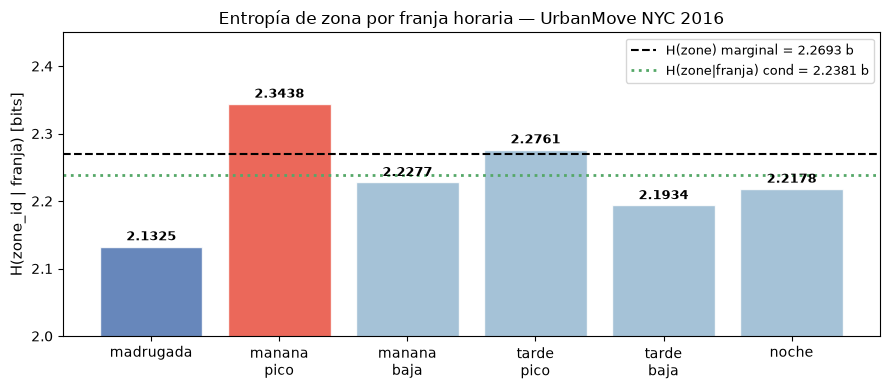

Figura guardada en docs/fig_resumen_entropia_franja.png


In [13]:
# --- Gráfica resumen: barras de entropía por franja ---
fig, ax = plt.subplots(figsize=(9, 4))

franja_labels = [f.replace('_', '\n') for f in franja_order]
ents = [franja_entropies[f] for f in franja_order]
colors_f = ['#e84e3d' if v == max(ents) else '#4C72B0' if v == min(ents) else '#95b8d1' for v in ents]

bars = ax.bar(franja_labels, ents, color=colors_f, alpha=0.85, edgecolor='white')
ax.axhline(H_zone, color='black', ls='--', lw=1.5, label=f'H(zone) marginal = {H_zone:.4f} b')
ax.axhline(H_cond_zone_franja, color='#55a868', ls=':', lw=2,
           label=f'H(zone|franja) cond = {H_cond_zone_franja:.4f} b')

for bar, val in zip(bars, ents):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{val:.4f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

ax.set_ylabel('H(zone_id | franja) [bits]', fontsize=11)
ax.set_title('Entropía de zona por franja horaria — UrbanMove NYC 2016', fontsize=12)
ax.legend(fontsize=9)
ax.set_ylim(2.0, 2.45)
plt.tight_layout()
plt.savefig(r'..\docs\fig_resumen_entropia_franja.png', dpi=120, bbox_inches='tight')
plt.show()
print('Figura guardada en docs/fig_resumen_entropia_franja.png')

---
## Hallazgos Finales para UrbanMove

El análisis de teoría de la información sobre 50,000 viajes de taxis en NYC revela cuatro hallazgos accionables:

**1. La demanda es intrínsecamente difusa (H = 2.2693 bits por zona).**  
Con 33 zonas activas y una entropía de 2.27 bits, la distribución de orígenes está lejos de concentrarse en pocas zonas. Una distribución perfectamente uniforme en 33 zonas tendría 5.04 bits; la real (2.27 bits) indica que ya hay concentración importante (~56% del máximo posible), pero queda incertidumbre residual que no puede eliminarse con variables temporales solas.

**2. La hora del día aporta muy poca información sobre la zona de origen (MI = 0.0440 bits, 1.94 %).**  
Saber a qué hora se pide un taxi reduce la incertidumbre sobre la zona de recogida en apenas el 1.94 %. UrbanMove no puede despachar conductores eficientemente basándose solo en la hora. Se requieren variables adicionales: barrio de residencia, eventos programados, clima.

**3. Días laborales y fines de semana son distribuciones distintas (KL = 0.1636 bits, overhead +3.71 %).**  
La divergencia KL de 0.164 bits equivale a un overhead del 3.71 % al usar un modelo de fin de semana para predecir el comportamiento laboral. Las diferencias se concentran en h=01–03 a.m. (3× más viajes en fin de semana) y h=07–08 a.m. (3× más viajes en días laborales). UrbanMove necesita **dos políticas de despacho separadas**.

**4. La madrugada es la franja más concentrada (H = 2.1325 bits) y la mañana pico la más dispersa (H = 2.3438 bits).**  
La hora pico por volumen es h=19 (3,168 viajes, H=2.1622 bits). Durante la madrugada, los pocos viajes se concentran en zonas bien definidas (Manhattan, aeropuertos), lo que permite cubrir el turno con menos conductores posicionados en esas zonas específicas. En la mañana pico, los commuters salen desde múltiples barrios residenciales — la dispersión es mayor y requiere cobertura geográfica amplia.